---
title: 'Solutions: Introduction to Generative Adversarial Networks'
author: Mark Fuge
format:
    html:
        code-fold: true
        code-summary: "Show Solution Code"
---

These are worked solutions to the exercises at the end of the chapter *Introduction to Push-Forward Generative Models -- Generative Adversarial Networks (GANs)*.

In [1]:
import copy
import sys

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from matplotlib import pyplot as plt

sys.path.insert(0, '../part2/gen_models')
from gen_models_utilities import RNG_SEED, device, create_ring_gaussians, GanHistory, make_loader, compute_diversity_metric

# The chapter's ring data (first use of NumPy's global generator after the seed in gen_models_utilities)
X_ring, y_ring = create_ring_gaussians()

In [2]:
# The chapter's networks and training loop
class MLPGenerator(nn.Module):
    def __init__(self, noise_dim: int = 2, hidden_dim: int = 256, out_dim: int = 2):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(noise_dim, hidden_dim), nn.LeakyReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.LeakyReLU(),
            nn.Linear(hidden_dim, out_dim),
)
    def forward(self, z: torch.Tensor) -> torch.Tensor:
        return self.main(z)

class MLPDiscriminator(nn.Module):
    def __init__(self, input_dim: int = 2, hidden_dim: int = 256):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim), nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, 1),
)
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.main(x).squeeze(-1)

def build_generator(noise_dim=2, hidden_dim=256):
    return MLPGenerator(noise_dim=noise_dim, hidden_dim=hidden_dim).to(device)

def build_discriminator(hidden_dim=256):
    return MLPDiscriminator(hidden_dim=hidden_dim).to(device)


def train_vanilla_gan(
    data: np.ndarray, *, noise_dim: int = 2, batch_size: int = 256, epochs: int = 120,
    lr_g: float = 2e-4, lr_d: float = 2e-4, hidden_dim: int = 256, print_every: int = 40) -> tuple[nn.Module, nn.Module, GanHistory]:
    # Load the data into a DataLoader for batching and make PyTorch happy
    loader = make_loader(data, batch_size)

    # Set up the basic networks
    G = build_generator(noise_dim=noise_dim, hidden_dim=hidden_dim)
    D = build_discriminator(hidden_dim=hidden_dim)
    # Instantiate the optimizers for each model
    opt_g = optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    opt_d = optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    # Record the loss history for plotting later
    hist = GanHistory([], [], [], [], [])

    # Now we do the training loop for # epochs defined in `epochs`
    for ep in range(epochs):
        d_losses=[]
        g_losses=[]
        real_scores=[]
        fake_scores=[]
        for (xb,) in loader:
            # Send the data to the GPU, if using.
            xb = xb.to(device)

            # Take a Discriminator step
            z = torch.randn(xb.size(0), noise_dim, device=device)
            with torch.no_grad():
                x_fake = G(z)
            opt_d.zero_grad()
            d_real = D(xb)
            d_fake = D(x_fake)
            loss_d = bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))
            loss_d.backward()
            opt_d.step()
            d_losses.append(float(loss_d.detach().cpu().item()))
            real_scores.append(d_real.mean().item())
            fake_scores.append(d_fake.mean().item())

            # Take a Generator step
            z = torch.randn(xb.size(0), noise_dim, device=device)
            opt_g.zero_grad()
            xg = G(z)
            dg = D(xg)
            loss_g = bce(dg, torch.ones_like(dg))
            loss_g.backward()
            opt_g.step()
            g_losses.append(float(loss_g.detach().cpu().item()))
        
        # We'll record some epoch metrics
        with torch.no_grad():
            z_eval = torch.randn(2048, noise_dim, device=device)
            samples = G(z_eval)
            div = compute_diversity_metric(samples)

        # Now we'll record the metrics for plotting later and reporting
        hist.d_loss.append(float(np.mean(d_losses)))
        hist.g_loss.append(float(np.mean(g_losses)))
        hist.diversity.append(div)
        hist.real_scores.append(float(np.mean(real_scores)))
        hist.fake_scores.append(float(np.mean(fake_scores)))
        if (ep+1) % max(1, print_every) == 0 or ep==0:
            print(f"Epoch {ep+1:03d}/{epochs} | D {hist.d_loss[-1]:.3f} | G {hist.g_loss[-1]:.3f} | Div {div:.3f}")
    return G, D, hist

In [3]:
# The chapter's GAN, trained as in the chapter
G, D, H = train_vanilla_gan(
    X_ring, epochs=120, batch_size=256, 
    lr_g=2e-4, lr_d=2e-4, 
    hidden_dim=256, noise_dim=2, 
    print_every=40)

Epoch 001/120 | D 1.128 | G 0.734 | Div 0.809
Epoch 040/120 | D 1.300 | G 0.769 | Div 4.310
Epoch 080/120 | D 1.340 | G 0.754 | Div 4.409
Epoch 120/120 | D 1.368 | G 0.732 | Div 4.444


In [4]:
# The helpers from 'What the Discriminator Looks Like'
import copy

# A fixed set of latent vectors, so every map below shows the same generator samples
Z_SHOW = torch.randn(500, 2, generator=torch.Generator().manual_seed(RNG_SEED)).to(device)


def generator_push(D_net, x_fake):
    # Direction that lowers the generator loss -log(sigmoid(logit)) at each fake sample
    x = x_fake.clone().requires_grad_(True)
    loss_g = nn.functional.binary_cross_entropy_with_logits(D_net(x), torch.ones(len(x), device=device), reduction='sum')
    loss_g.backward()
    return -x.grad


def plot_discriminator_map(D_net, G_net, ax=None, arrows=False, n_arrows=150, lim=None, title='', X_real=None):
    # D's logit over the data space, the real data (the ring unless X_real is given),
    # the generator's samples and (optionally) their push
    if X_real is None:
        X_real = X_ring
    if ax is None:
        fig, ax = plt.subplots(figsize=(6.5, 5.5))
    with torch.no_grad():
        x_fake = G_net(Z_SHOW)
    fake_np = x_fake.cpu().numpy()
    if lim is None:
        # Show at least [-5, 5] x [-5, 5], and widen the window if the generator's samples lie outside it
        lim = max(5.0, 1.1 * np.percentile(np.abs(fake_np).max(axis=1), 99))
    grid_1d = np.linspace(-lim, lim, 201)
    xx, yy = np.meshgrid(grid_1d, grid_1d)
    grid = torch.tensor(np.stack([xx.ravel(), yy.ravel()], axis=1), dtype=torch.float32, device=device)
    with torch.no_grad():
        logit = D_net(grid).cpu().numpy().reshape(xx.shape)
    v = np.abs(logit).max()
    im = ax.contourf(xx, yy, logit, levels=np.linspace(-v, v, 31), cmap='RdBu_r')
    ax.contour(xx, yy, logit, levels=[0], colors='k', linewidths=0.8)
    ax.scatter(X_real[:800, 0], X_real[:800, 1], s=4, color='0.35', alpha=0.4, label='Real')
    ax.scatter(fake_np[:, 0], fake_np[:, 1], s=6, color='tab:orange', label='Generated')
    if arrows:
        push = generator_push(D_net, x_fake[:n_arrows]).cpu().numpy()
        # The longest arrow is 16% of the window's half-width; only directions and relative lengths matter
        ax.quiver(fake_np[:n_arrows, 0], fake_np[:n_arrows, 1], push[:, 0], push[:, 1], color='darkgreen',
                  angles='xy', scale_units='xy', scale=np.linalg.norm(push, axis=1).max() / (0.16 * lim), width=0.004)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_title(title, fontsize=11)
    plt.colorbar(im, ax=ax, fraction=0.046, label='Discriminator logit')
    return ax

### Exercise 1: One step at a time

Epoch 001/3 | D 1.261 | G 0.728 | Div 0.621
Epoch 003/3 | D 1.467 | G 0.805 | Div 2.755
Epoch 001/5 | D 1.261 | G 0.728 | Div 0.621
Epoch 005/5 | D 1.465 | G 0.791 | Div 1.170


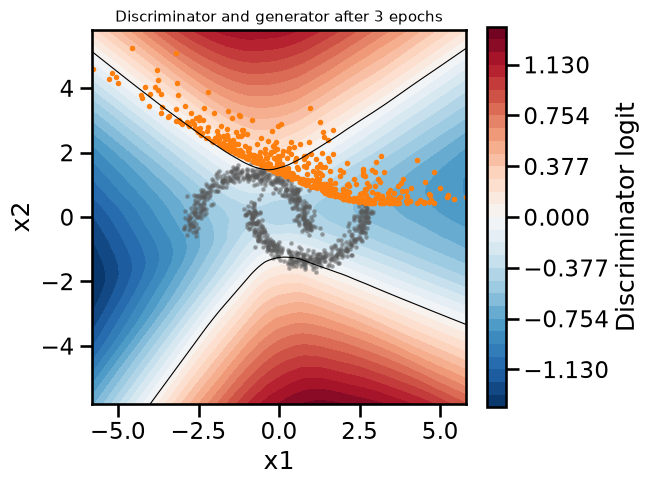

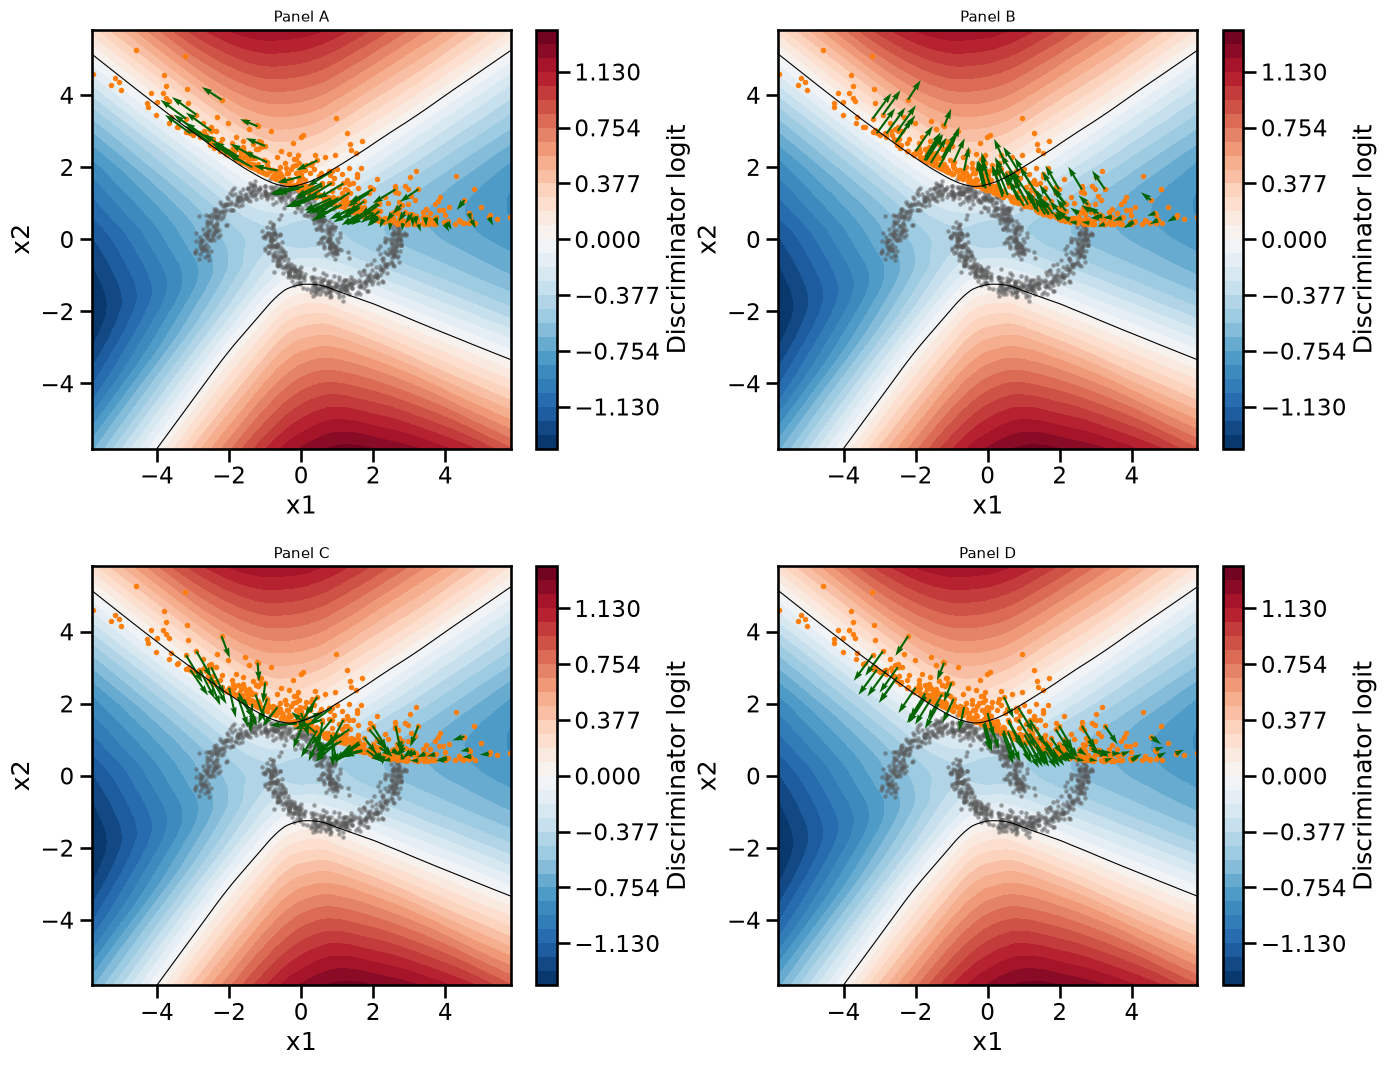

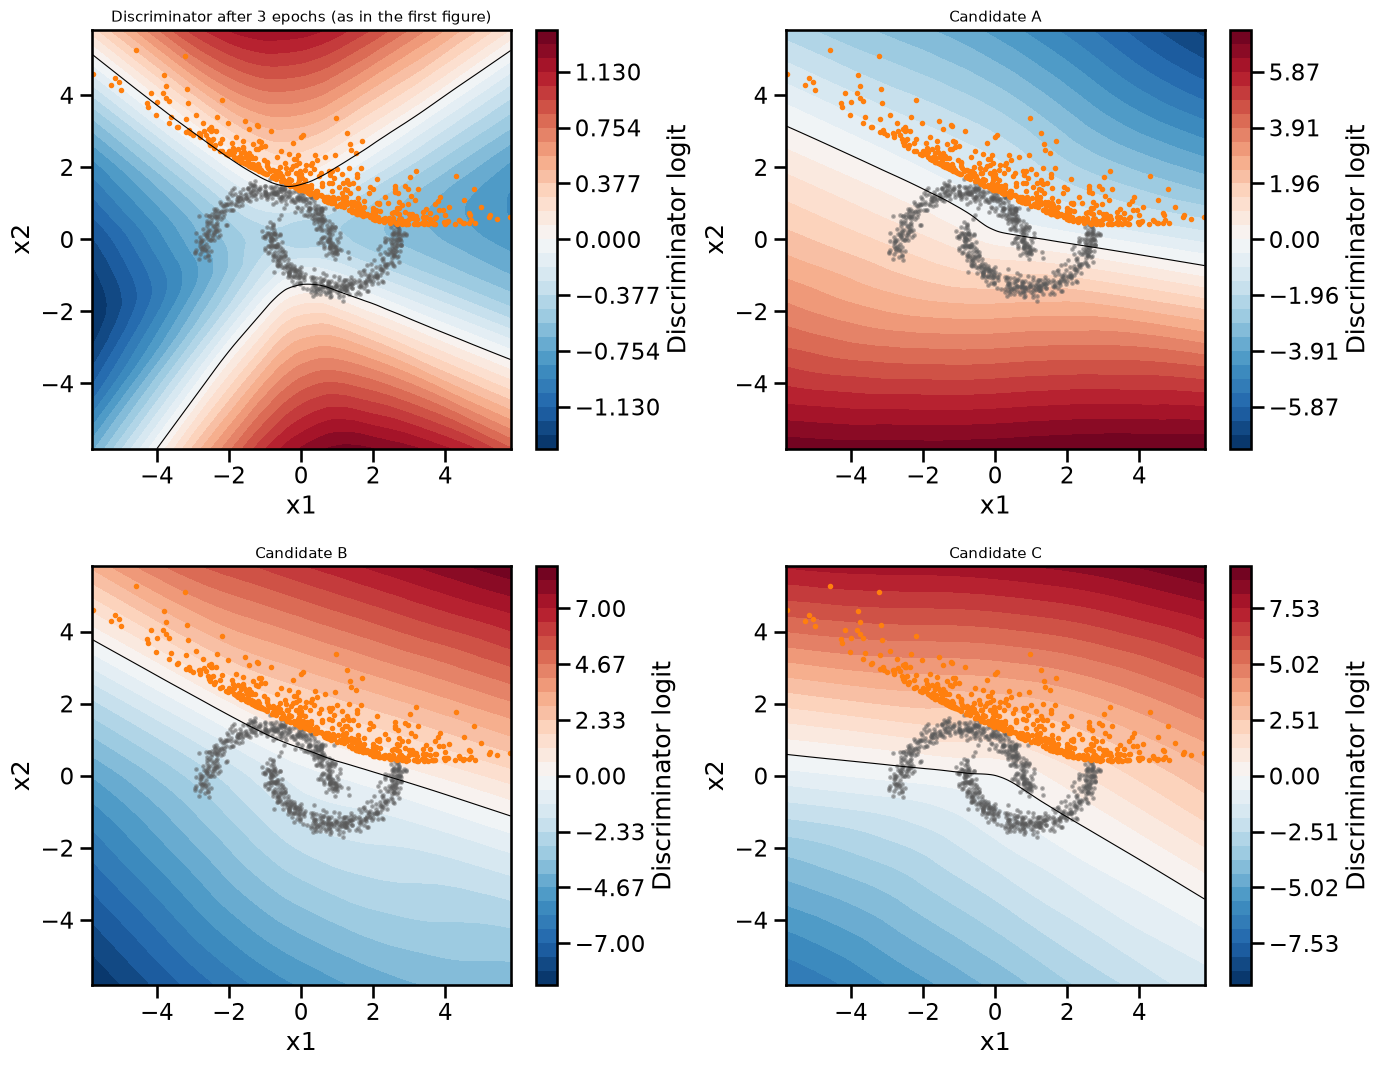

In [5]:
# Figures for Exercise 1: the chapter's GAN after 3 epochs on two moons, four arrow fields, three candidate discriminators
from sklearn.datasets import make_moons

EX1_EPOCHS = 3        # the snapshot shown in the figures
EX1_LATER_EPOCHS = 5  # the same run two epochs later (its samples train one of the candidates)
EX1_D_STEPS = 25      # discriminator steps from the snapshot for the candidates
EX1_ARROWS = 80       # samples that get an arrow

X_moons, _ = make_moons(5000, noise=0.08, random_state=RNG_SEED)
X_moons = (1.8 * (X_moons - X_moons.mean(axis=0))).astype(np.float32)

torch.manual_seed(RNG_SEED)
G_moons, D_moons, _ = train_vanilla_gan(X_moons, epochs=EX1_EPOCHS, print_every=EX1_EPOCHS)
torch.manual_seed(RNG_SEED)
G_moons_later, _, _ = train_vanilla_gan(X_moons, epochs=EX1_LATER_EPOCHS, print_every=EX1_LATER_EPOCHS)


def train_discriminator(D_start, G_net, steps, swap_labels=False, batch_size=256, lr=2e-4, seed=RNG_SEED):
    # Discriminator steps as in the chapter's loop, on a copy of D_start, against samples of a frozen G_net
    torch.manual_seed(seed)
    D_new = copy.deepcopy(D_start)
    opt_d = optim.Adam(D_new.parameters(), lr=lr, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    X_t = torch.from_numpy(X_moons).to(device)
    real_label, fake_label = (0.0, 1.0) if swap_labels else (1.0, 0.0)
    for step in range(steps):
        xb = X_t[torch.randint(0, len(X_t), (batch_size,), device=device)]
        with torch.no_grad():
            x_fake = G_net(torch.randn(batch_size, 2, device=device))
        opt_d.zero_grad()
        loss_d = (bce(D_new(xb), torch.full((batch_size,), real_label, device=device))
                  + bce(D_new(x_fake), torch.full((batch_size,), fake_label, device=device)))
        loss_d.backward()
        opt_d.step()
    return D_new


# Four arrow fields on the same samples, all with the length of the true push
with torch.no_grad():
    x_show = G_moons(Z_SHOW)
fake_np = x_show.cpu().numpy()
lim_moons = max(5.0, 1.1 * np.percentile(np.abs(fake_np).max(axis=1), 99))
push = generator_push(D_moons, x_show[:EX1_ARROWS]).cpu().numpy()
push_len = np.linalg.norm(push, axis=1, keepdims=True)
X_moons_t = torch.from_numpy(X_moons).to(device)
to_nearest = (X_moons_t[torch.cdist(x_show[:EX1_ARROWS], X_moons_t).argmin(dim=1)] - x_show[:EX1_ARROWS]).cpu().numpy()
arrow_fields = {'A': np.stack([-push[:, 1], push[:, 0]], axis=1),                         # along the contours
                'B': push,                                                               # true push
                'C': to_nearest / np.linalg.norm(to_nearest, axis=1, keepdims=True) * push_len,  # toward nearest real point
                'D': -push}                                                              # reversed

# The discriminator after EX1_EPOCHS epochs and the generator's samples
plot_discriminator_map(D_moons, G_moons, lim=lim_moons, X_real=X_moons,
                       title=f'Discriminator and generator after {EX1_EPOCHS} epochs')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (letter, field) in zip(axes.ravel(), arrow_fields.items()):
    plot_discriminator_map(D_moons, G_moons, ax=ax, lim=lim_moons, X_real=X_moons, title=f'Panel {letter}')
    ax.quiver(fake_np[:EX1_ARROWS, 0], fake_np[:EX1_ARROWS, 1], field[:, 0], field[:, 1], color='darkgreen',
              angles='xy', scale_units='xy', scale=push_len.max() / (0.16 * lim_moons), width=0.005)
plt.tight_layout()
plt.show()

# Three candidate discriminators after a short burst of discriminator steps from D_moons
candidates = {'A': train_discriminator(D_moons, G_moons, EX1_D_STEPS),                     # against the samples shown
              'B': train_discriminator(D_moons, G_moons, EX1_D_STEPS, swap_labels=True),   # real/fake labels swapped
              'C': train_discriminator(D_moons, G_moons_later, EX1_D_STEPS)}               # against another generator's samples
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
plot_discriminator_map(D_moons, G_moons, ax=axes[0, 0], lim=lim_moons, X_real=X_moons,
                       title=f'Discriminator after {EX1_EPOCHS} epochs (as in the first figure)')
for ax, (letter, D_cand) in zip(axes.ravel()[1:], candidates.items()):
    plot_discriminator_map(D_cand, G_moons, ax=ax, lim=lim_moons, X_real=X_moons, title=f'Candidate {letter}')
plt.tight_layout()
plt.show()

(a) median cosine between the true push and the direction to the nearest real point: -0.40
    panel A: median cosine with the true push +0.00
    panel B: median cosine with the true push +1.00
    panel C: median cosine with the true push -0.40
    panel D: median cosine with the true push -1.00
(a) at the arrows: logit from -0.80 to 0.52, 1 - sigmoid(logit) from 0.37 to 0.69, slope of the logit from 0.08 to 0.44, push length from 0.053 to 0.220
    mean push length for samples with x1 < 0: 0.185 (slope 0.39, 1 - sigmoid 0.47); with x1 > 2: 0.078 (slope 0.12, 1 - sigmoid 0.65)
    correlation of the push length with 1 - sigmoid(logit) -0.73, with the slope 0.97
    mean push direction (x1, x2): (-0.030, +0.113); mean position of the samples (0.59, 1.58), of the real data (0.00, 0.00)
(b) later generator: mean sample position (-0.23, -1.03)
    candidate A: mean logit change at the samples shown -1.02, at the real data +0.88, at the later generator's samples +1.92
    candidate B: mea

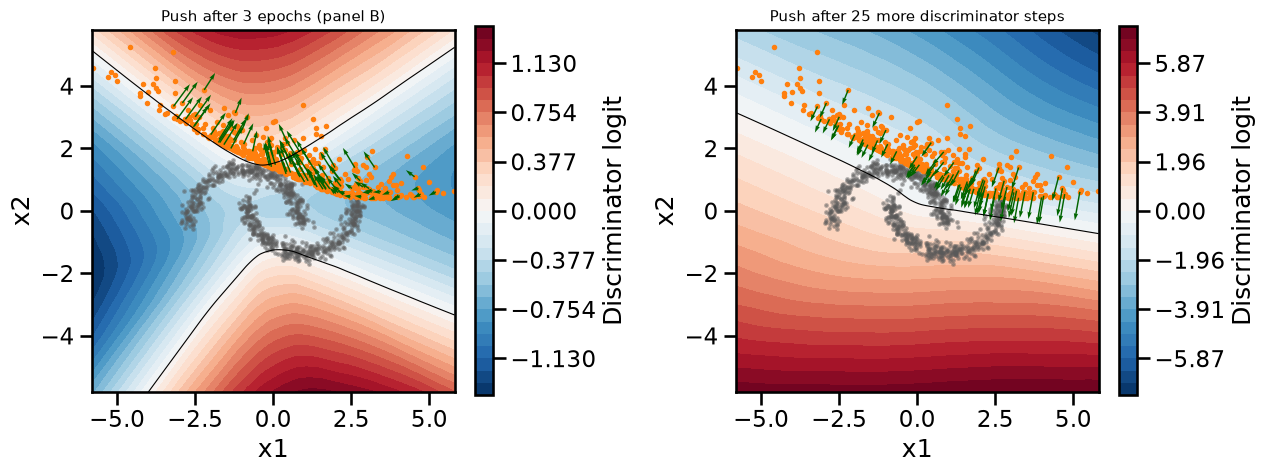

In [6]:
# G_moons, D_moons, x_show, push, to_nearest, arrow_fields and candidates come from the figure cell above
def median_cosine(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return float(np.median((a * b).sum(axis=1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))))


print(f'(a) median cosine between the true push and the direction to the nearest real point: {median_cosine(push, to_nearest):.2f}')
for letter, field in arrow_fields.items():
    print(f'    panel {letter}: median cosine with the true push {median_cosine(field, push):+.2f}')

# Length of the push = (1 - sigmoid(logit)) * |gradient of the logit|
x_arrows = x_show[:EX1_ARROWS].clone().requires_grad_(True)
logit_arrows = D_moons(x_arrows)
grad_logit = torch.autograd.grad(logit_arrows.sum(), x_arrows)[0].norm(dim=1).cpu().numpy()
factor = (1 - torch.sigmoid(logit_arrows)).detach().cpu().numpy()
length = np.linalg.norm(push, axis=1)
print(f'(a) at the arrows: logit from {logit_arrows.min().item():.2f} to {logit_arrows.max().item():.2f}, '
      f'1 - sigmoid(logit) from {factor.min():.2f} to {factor.max():.2f}, '
      f'slope of the logit from {grad_logit.min():.2f} to {grad_logit.max():.2f}, '
      f'push length from {length.min():.3f} to {length.max():.3f}')
left, right = fake_np[:EX1_ARROWS, 0] < 0, fake_np[:EX1_ARROWS, 0] > 2
print(f'    mean push length for samples with x1 < 0: {length[left].mean():.3f} (slope {grad_logit[left].mean():.2f}, '
      f'1 - sigmoid {factor[left].mean():.2f}); with x1 > 2: {length[right].mean():.3f} '
      f'(slope {grad_logit[right].mean():.2f}, 1 - sigmoid {factor[right].mean():.2f})')
print(f'    correlation of the push length with 1 - sigmoid(logit) {np.corrcoef(length, factor)[0, 1]:.2f}, '
      f'with the slope {np.corrcoef(length, grad_logit)[0, 1]:.2f}')
print(f'    mean push direction (x1, x2): ({push[:, 0].mean():+.3f}, {push[:, 1].mean():+.3f}); '
      f'mean position of the samples ({fake_np[:, 0].mean():.2f}, {fake_np[:, 1].mean():.2f}), '
      f'of the real data ({X_moons[:, 0].mean():.2f}, {X_moons[:, 1].mean():.2f})')

# (b) How each candidate changed the logit, at the samples shown, at the real data and at the later generator's samples
with torch.no_grad():
    x_later = G_moons_later(Z_SHOW)
    print(f'(b) later generator: mean sample position ({x_later[:, 0].mean().item():.2f}, {x_later[:, 1].mean().item():.2f})')
    for letter, D_cand in candidates.items():
        print(f'    candidate {letter}: mean logit change at the samples shown {(D_cand(x_show) - D_moons(x_show)).mean().item():+.2f}, '
              f'at the real data {(D_cand(X_moons_t) - D_moons(X_moons_t)).mean().item():+.2f}, '
              f"at the later generator's samples {(D_cand(x_later) - D_moons(x_later)).mean().item():+.2f}")

# (c) The push after the discriminator's 25 steps (candidate A), on the same samples
push_after = generator_push(candidates['A'], x_show[:EX1_ARROWS]).cpu().numpy()
print(f'(c) after {EX1_D_STEPS} discriminator steps: median cosine with the old push {median_cosine(push_after, push):+.2f}, '
      f'with the direction to the nearest real point {median_cosine(push_after, to_nearest):+.2f}')
print(f'    mean push direction (x1, x2): ({push_after[:, 0].mean():+.3f}, {push_after[:, 1].mean():+.3f}); '
      f'share of samples pushed down (toward the data) {np.mean(push_after[:, 1] < 0):.2f} (before: {np.mean(push[:, 1] < 0):.2f})')

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (D_net, title) in zip(axes, [(D_moons, f'Push after {EX1_EPOCHS} epochs (panel B)'),
                                     (candidates['A'], f'Push after {EX1_D_STEPS} more discriminator steps')]):
    plot_discriminator_map(D_net, G_moons, ax=ax, arrows=True, n_arrows=EX1_ARROWS, lim=lim_moons, X_real=X_moons, title=title)
plt.tight_layout()
plt.show()

**(a)** Panel B. The generator's loss at a sample is $\mathcal{L}_G = -\log \sigma(\ell(x))$, so each sample moves along $-\nabla_x \mathcal{L}_G = (1 - \sigma(\ell))\, \nabla_x \ell$: straight up the logit of the discriminator shown, across its contours toward red. Panel B's arrows do that. Panel A's arrows run along the contours (median cosine with the true push 0.00), and panel D's point down the logit ($-1.00$). Panel C points each sample at its nearest real point, which looks sensible but is not what the generator does: the generator never sees the data, and panel C's median cosine with the true push is $-0.40$. Here the true push points mostly up (mean direction $(-0.030, +0.113)$), away from the moons below the samples, because this discriminator's logit happens to grow upward above the moons.

The length of an arrow is $1 - \sigma(\ell)$ times the slope of the logit. At the arrows the slope ranges from 0.08 to 0.44, while $1 - \sigma(\ell)$ only ranges from 0.37 to 0.69, so the slope sets the length (correlation 0.97). The arrows are longest on the left part of the arc (mean length 0.185 for $x_1 < 0$), where the contours lie close together, and shortest at the flat right end (0.078 for $x_1 > 2$). This holds although the samples at the right end sit at a lower logit, where the factor $1 - \sigma(\ell)$ is larger (0.65 against 0.47).

**(b)** Candidate A. A discriminator step lowers the logit at the current generated samples and raises it at the real data. In candidate A the mean logit drops by 1.02 at the samples shown and rises by 0.88 at the real data, so the samples now sit in blue and the moons in red. Candidate B does the opposite (+1.53 at the samples, $-0.57$ at the real data): it was trained with the real and fake labels swapped. Candidate C raises the logit at the samples shown by 2.76. It was trained against the samples of the same run two epochs later, which lie below the moons (mean position $(-0.23, -1.03)$), and lowered the logit there instead ($-0.56$). It rejects a generator that is not the one shown.


### Exercise 2: Seven generators, one score

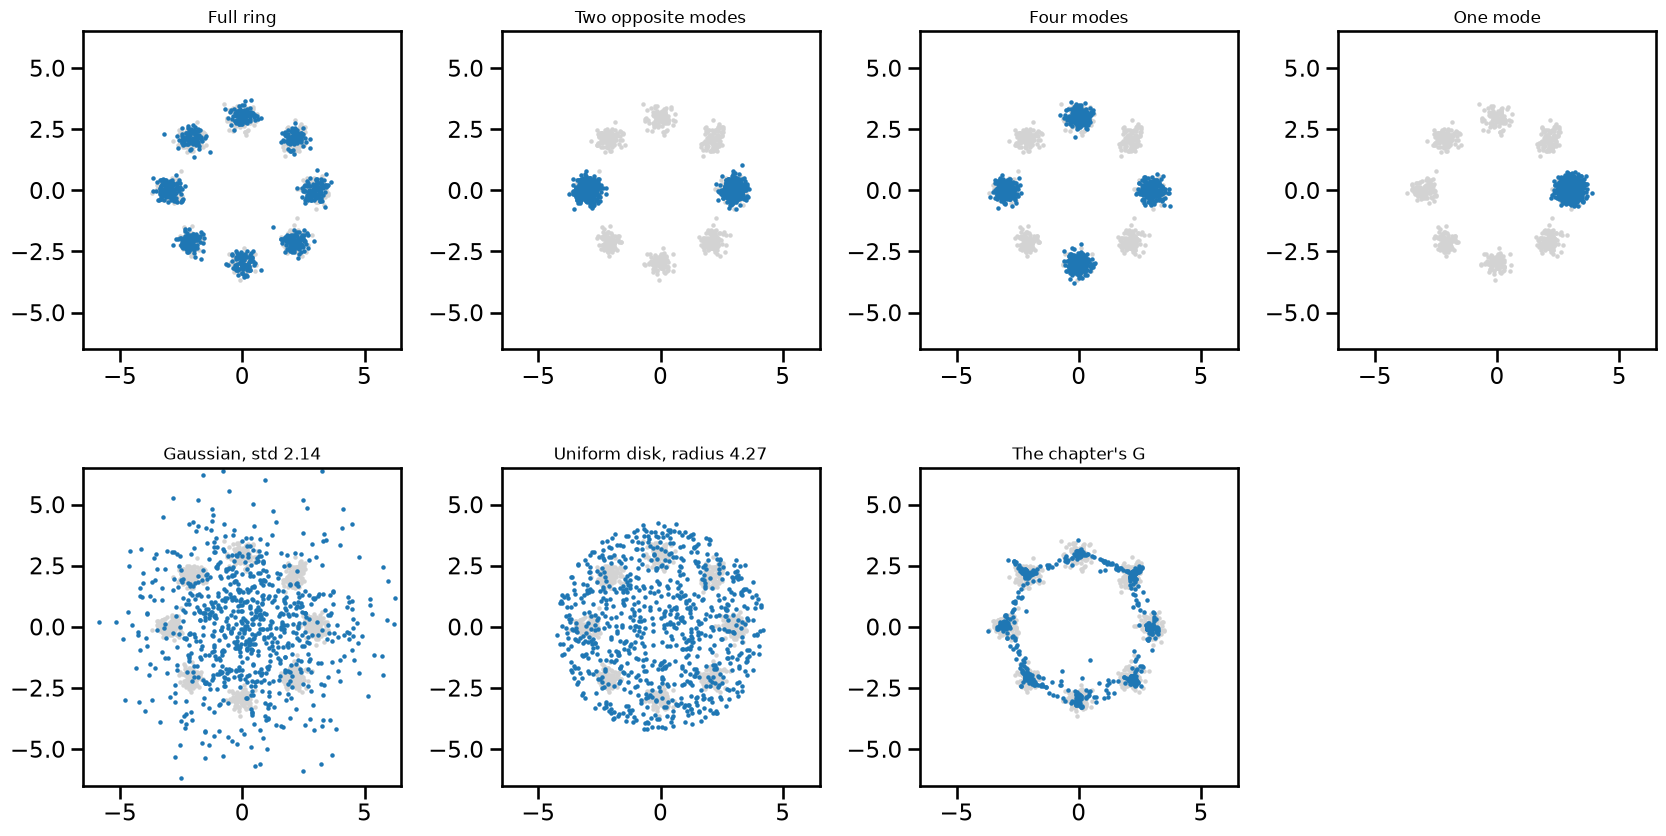

In [7]:
# Figure for Exercise 2: seven sample sets of 2048 points (their diversity scores are printed further below)
rng_ex2 = np.random.default_rng(RNG_SEED)
n_ex2 = 2048
ring_angles = np.linspace(0, 2 * np.pi, 8, endpoint=False)
ring_centers = 3.0 * np.stack([np.cos(ring_angles), np.sin(ring_angles)], axis=1)


def ring_modes(modes):
    # Equal-weight Gaussian blobs (std 0.25) at the chosen mode centers of the ring
    pick = rng_ex2.choice(modes, n_ex2)
    return ring_centers[pick] + 0.25 * rng_ex2.standard_normal((n_ex2, 2))


disk_r = 4.272 * np.sqrt(rng_ex2.random(n_ex2))
disk_t = 2 * np.pi * rng_ex2.random(n_ex2)
torch.manual_seed(RNG_SEED)
with torch.no_grad():
    samples_G = G(torch.randn(n_ex2, 2, device=device)).cpu().numpy()

sample_sets = {
    'Full ring': ring_modes(np.arange(8)),
    'Two opposite modes': ring_modes([0, 4]),
    'Four modes': ring_modes([0, 2, 4, 6]),
    'One mode': ring_modes([0]),
    'Gaussian, std 2.14': 2.136 * rng_ex2.standard_normal((n_ex2, 2)),
    'Uniform disk, radius 4.27': np.stack([disk_r * np.cos(disk_t), disk_r * np.sin(disk_t)], axis=1),
    "The chapter's G": samples_G,
}
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for ax, (name, s) in zip(axes.ravel(), sample_sets.items()):
    ax.scatter(X_ring[:800, 0], X_ring[:800, 1], s=3, color='lightgray')
    ax.scatter(s[:800, 0], s[:800, 1], s=3, color='tab:blue')
    ax.set_title(name, fontsize=12)
    ax.set_xlim(-6.5, 6.5)
    ax.set_ylim(-6.5, 6.5)
    ax.set_aspect('equal')
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

In [8]:
for name, s in sample_sets.items():
    s = np.asarray(s)
    print(f'{name:28s} diversity {compute_diversity_metric(torch.from_numpy(s.astype(np.float32))):.3f}   '
          f'per-axis variances {np.round(s.var(axis=0), 2)}')
print(f'Ring modes, theory: r^2/2 + sigma^2 = {3.0**2 / 2 + 0.25**2:.4f}')

Full ring                    diversity 4.556   per-axis variances [4.57 4.54]
Two opposite modes           diversity 4.537   per-axis variances [9.01 0.07]
Four modes                   diversity 4.569   per-axis variances [4.54 4.6 ]
One mode                     diversity 0.062   per-axis variances [0.06 0.06]
Gaussian, std 2.14           diversity 4.689   per-axis variances [4.58 4.8 ]
Uniform disk, radius 4.27    diversity 4.578   per-axis variances [4.57 4.59]
The chapter's G              diversity 4.419   per-axis variances [4.49 4.35]
Ring modes, theory: r^2/2 + sigma^2 = 4.5625


**(a)** A good ranking, from the best generator of the ring to the worst: the full ring and the chapter's `G` come first. Both cover all eight modes, and `G` adds a thin trail between them. Four modes and then two modes come next. They have the right shape but miss part of the ring. The uniform disk and the Gaussian follow. Their spread is about right, but they put most of their samples where there is no data. The single mode comes last. You might expect the scores to follow this order. They do not. Six of the seven sets score between 4.42 and 4.69, and only the single mode stands out, with 0.062.

**(b)** The five sets that score about 4.5 are the full ring (4.556), the two opposite modes (4.537), the four modes (4.569), the Gaussian (4.689) and the uniform disk (4.578). `compute_diversity_metric` returns the variance along each axis, averaged over the two axes. For a set centered at the origin, this is half the mean squared distance from the origin. So the metric measures how far the samples spread, and nothing else. It does not see where the samples are or how many modes they cover.

Every ring mode sits at distance $r = 3$ from the origin, with spread $\sigma = 0.25$. Any equal-weight set of modes whose mean is the origin therefore has diversity $r^2/2 + \sigma^2 = 4.5625$, whether it has 2, 4 or 8 modes. The two opposite modes get there in a very different way: variance 9.01 along the first axis and 0.07 along the second, with mean 4.537. The Gaussian (standard deviation $2.136 = \sqrt{4.5625}$) and the uniform disk (radius $R = 4.272$, variance $R^2/4 = 4.5625$ per axis) were built to have the same spread. The single mode is not centered at the origin. Its variance is only $\sigma^2 = 0.0625$, measured as 0.062.

::: {.callout-note collapse="true"}
### Derivation of the diversity of a centered set of ring modes
Let $x = \mu_k + \epsilon$, where the mode center $\mu_k$ with $\|\mu_k\| = r$ is picked with equal probability from a set whose mean is zero, and $\epsilon \sim N(0, \sigma^2 I)$ is independent of $k$. Then $\mathbb{E}[x] = 0$ and

$$
\operatorname{Var}(x_1) + \operatorname{Var}(x_2) = \mathbb{E}\|x\|^2 = \mathbb{E}\|\mu_k\|^2 + \mathbb{E}\|\epsilon\|^2 = r^2 + 2\sigma^2,
$$

so the mean per-axis variance is $r^2/2 + \sigma^2$. The number of modes only enters through the condition that their mean is zero, which holds for 2 opposite, 4 or 8 equally spaced modes.
:::

**(c)** No. The chapter's `G` scores 4.419, below the Gaussian's 4.689, but it is clearly the better generator of the ring. Its samples lie on the ring and cover all eight modes, while the Gaussian puts most of its samples where there is no data. `G` also scores a little below the full ring (4.556). Its trail between the modes runs inside the ring, along chords whose midpoints lie at radius $3 \cos(\pi/8) = 2.77$, and points closer to the origin lower the variance. A higher score does not mean a better generator. The right spread with the wrong shape scores just as well.

To judge a generator, compare the whole distribution of its samples with the data. In two dimensions you can plot the samples on top of the data and count the samples near each mode. You can also read the discriminator's map, as in *What the Discriminator Looks Like*, or compute a distance between the two sample sets, such as the optimal transport distances of the chapter *Optimal Transport for Generative Models*.

### Exercise 3: It looks like a beam

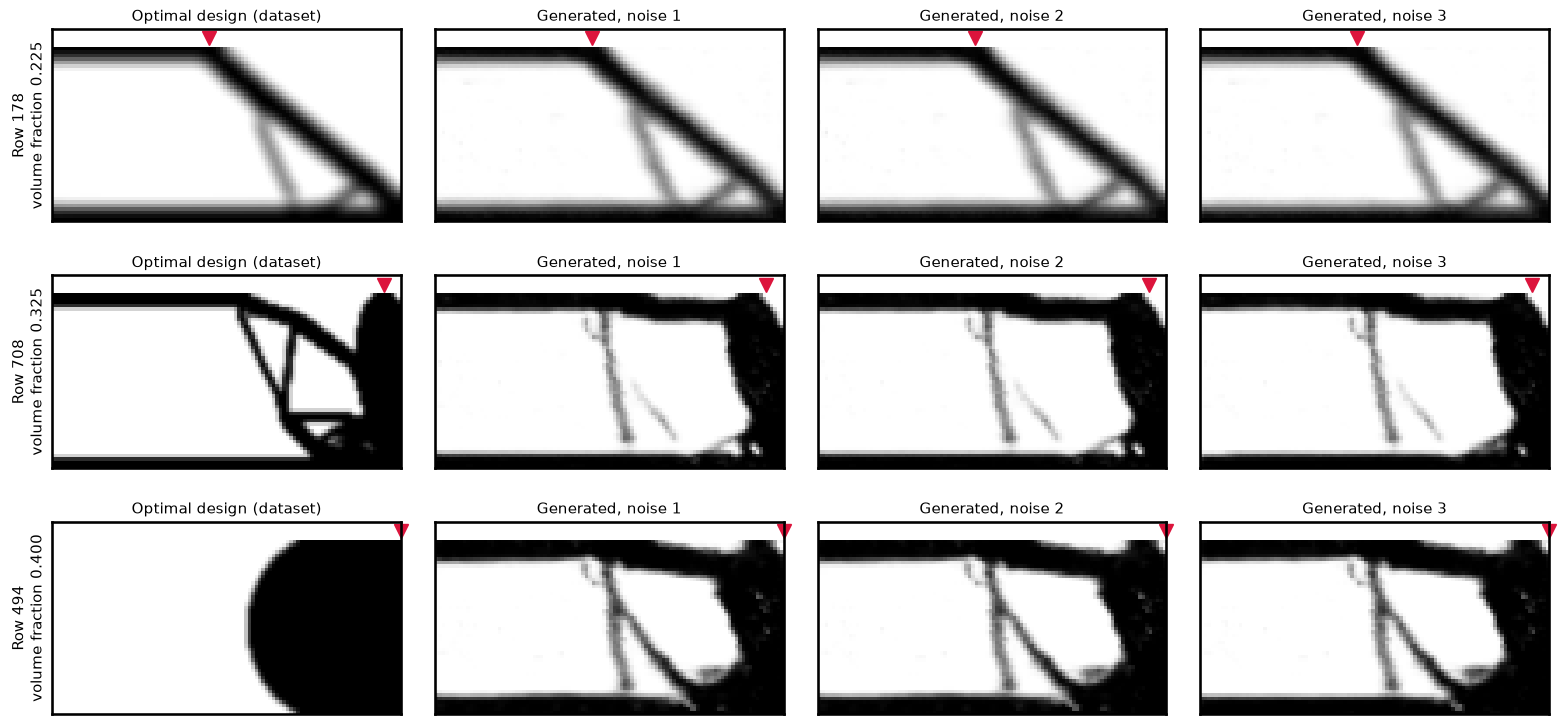

In [9]:
from engibench.problems.beams2d import Beams2D
from engibench_gen_models import CGANGenerator

BEAMS_GENERATOR_PATH = '../data/beams2d_cgan_generator.pth'
EX3_ROWS = [178, 708, 494]  # rows of the Beams2D validation set used in Exercise 3

beams = Beams2D()
beam_keys = beams.conditions_keys  # volfrac, rmin, forcedist, overhang_constraint
beams_val = beams.dataset['val']

# latent_dim=32 as in the training run that produced the weights (beams2d_cgan_cnn_2d, seed 1)
G_beams = CGANGenerator(latent_dim=32, n_conds=len(beam_keys), design_shape=(50, 100))
G_beams.load_state_dict(torch.load(BEAMS_GENERATOR_PATH, map_location='cpu'))
G_beams.eval()

torch.manual_seed(RNG_SEED)
z_beams = torch.randn(3, 32, 1, 1)  # three noise vectors, used for every row

beam_conditions, beam_optima, beam_designs = [], [], []
for i in EX3_ROWS:
    cond = {k: beams_val[k][i] for k in beam_keys}
    c = torch.tensor([[float(cond[k]) for k in beam_keys]] * 3, dtype=torch.float32).view(3, -1, 1, 1)
    with torch.no_grad():
        # The generator ends in tanh, so map its output from [-1, 1] to densities in [0, 1]
        designs = ((G_beams(z_beams, c) + 1) / 2).numpy().reshape(3, 50, 100)
    beam_conditions.append(cond)
    beam_optima.append(np.array(beams_val['optimal_design'][i]))
    beam_designs.append(designs)

fig, axes = plt.subplots(len(EX3_ROWS), 4, figsize=(16, 2.6 * len(EX3_ROWS)))
for r, (i, cond) in enumerate(zip(EX3_ROWS, beam_conditions)):
    images = [beam_optima[r]] + list(beam_designs[r])
    titles = ['Optimal design (dataset)', 'Generated, noise 1', 'Generated, noise 2', 'Generated, noise 3']
    for ax, im, title in zip(axes[r], images, titles):
        ax.imshow(im, cmap='gray_r', vmin=0, vmax=1, extent=(0, 100, 50, 0))
        ax.plot([100 * cond['forcedist']], [-2.5], marker='v', color='crimson', markersize=10, clip_on=False)  # just above the top edge, so it hides no elements
        ax.set_title(title, fontsize=11)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[r, 0].set_ylabel(f"Row {i}\nvolume fraction {cond['volfrac']:.3f}", fontsize=11)
plt.tight_layout()
plt.show()

In [10]:
print(f"{'Row':>4} {'design':>10} {'vol. frac.':>10} {'target':>7} {'constraints':>12} {'compliance':>11} {'ratio to optimum':>17}")
for r, (i, cond) in enumerate(zip(EX3_ROWS, beam_conditions)):
    # Beams2D.simulate sets up its load case on the first call and keeps it,
    # so each condition gets a fresh Beams2D object.
    simulator = Beams2D()
    c_opt = float(simulator.simulate(beam_optima[r], config=cond)[0])
    for name, design in [('optimum', beam_optima[r])] + [(f'noise {k + 1}', d) for k, d in enumerate(beam_designs[r])]:
        violations = beams.check_constraints(design, config=cond)
        compliance = float(simulator.simulate(design, config=cond)[0])
        print(f"{i:>4} {name:>10} {design.mean():>10.3f} {cond['volfrac']:>7.3f} "
              f"{'pass' if not violations else 'fail':>12} {compliance:>11.1f} {compliance / c_opt:>17.3g}")

 Row     design vol. frac.  target  constraints  compliance  ratio to optimum
 178    optimum      0.225   0.225         pass       111.0                 1
 178    noise 1      0.227   0.225         pass       115.1              1.04
 178    noise 2      0.227   0.225         pass       115.2              1.04
 178    noise 3      0.221   0.225         pass       118.9              1.07
 708    optimum      0.325   0.325         pass        14.1                 1
 708    noise 1      0.307   0.325         fail     69037.3           4.9e+03
 708    noise 2      0.307   0.325         fail     43874.4          3.11e+03
 708    noise 3      0.305   0.325         fail     35380.3          2.51e+03
 494    optimum      0.400   0.400         pass        18.5                 1
 494    noise 1      0.397   0.400         pass     85550.8          4.62e+03
 494    noise 2      0.398   0.400         pass     15383.5               832
 494    noise 3      0.392   0.400         pass     11177.5     

Row 178: load at column 45 of 100; density of the top-row element(s) under the load: optimum 1.00, generated 0.97, 0.97, 0.97
   differences between the three generated designs (mean absolute density): 1-2 0.0007, 1-3 0.0084; generated 1 vs optimum 0.029
Row 708: load at column 95 of 100; density of the top-row element(s) under the load: optimum 1.00, generated 0.03, 0.04, 0.04
   differences between the three generated designs (mean absolute density): 1-2 0.0005, 1-3 0.0114; generated 1 vs optimum 0.164
Row 494: load at column 100 of 100; density of the top-row element(s) under the load: optimum 1.00, generated 0.06, 0.08, 0.09
   differences between the three generated designs (mean absolute density): 1-2 0.0014, 1-3 0.0117; generated 1 vs optimum 0.342


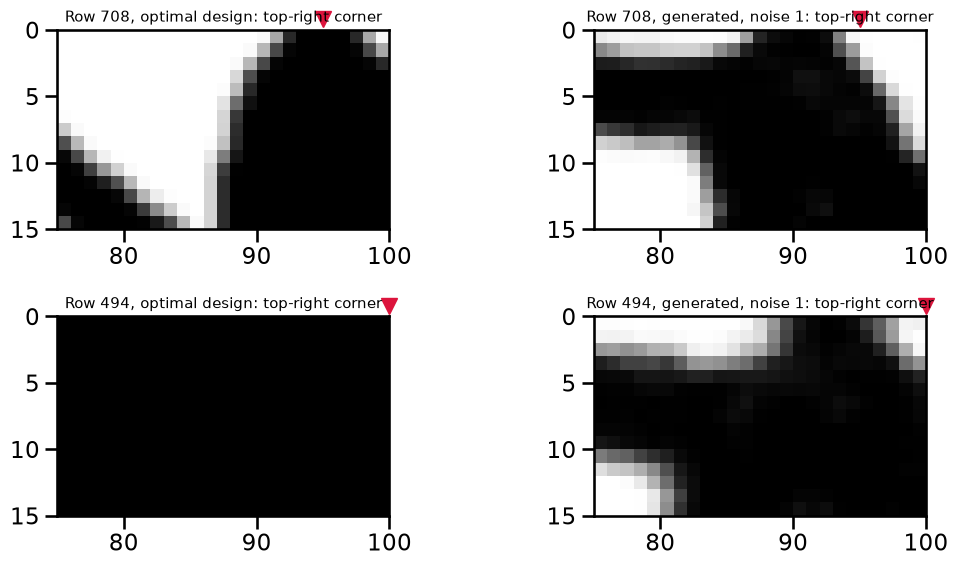

In [11]:
for r, i in enumerate(EX3_ROWS):
    cond = beam_conditions[r]
    load_column = int(round(100 * cond['forcedist']))
    cols = [c for c in (load_column - 1, load_column) if 0 <= c < 100]
    print(f"Row {i}: load at column {load_column} of 100; density of the top-row element(s) under the load: "
          f"optimum {beam_optima[r][0, cols].max():.2f}, generated "
          + ', '.join(f'{d[0, cols].max():.2f}' for d in beam_designs[r]))
    print('   differences between the three generated designs (mean absolute density): '
          f'1-2 {np.abs(beam_designs[r][0] - beam_designs[r][1]).mean():.4f}, '
          f'1-3 {np.abs(beam_designs[r][0] - beam_designs[r][2]).mean():.4f}; '
          f'generated 1 vs optimum {np.abs(beam_designs[r][0] - beam_optima[r]).mean():.3f}')

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, r in enumerate([1, 2]):
    for col, (im, title) in enumerate([(beam_optima[r], 'optimal design'), (beam_designs[r][0], 'generated, noise 1')]):
        ax = axes[row, col]
        ax.imshow(im, cmap='gray_r', vmin=0, vmax=1, extent=(0, 100, 50, 0))
        ax.plot([100 * beam_conditions[r]['forcedist']], [-0.8], marker='v', color='crimson', markersize=12, clip_on=False)
        ax.set_xlim(75, 100)
        ax.set_ylim(15, 0)
        ax.set_title(f'Row {EX3_ROWS[r]}, {title}: top-right corner', fontsize=11)
plt.tight_layout()
plt.show()

**(a)** From the pictures alone, row 178 looks like a near-copy of its optimum, so about the same compliance is a natural prediction. Row 708 has the same layout as its optimum, with a top chord, a post at the right end and diagonals, so perhaps a few times larger. Row 494 looks nothing like its optimum, a solid half-disk at the right end, so it is hard to guess. Visual similarity is what the generator was trained for, so it is all a picture can tell you.

**(b)** Row 178 is fine: the three designs have 1.04 to 1.07 times the optimal compliance and pass the constraint check. Rows 708 and 494 are far worse than any picture suggests. Row 708's designs have 2510 to 4900 times the optimal compliance, and row 494's have 604 to 4620 times. Row 708's designs fail `check_constraints` because they use slightly too little material (volume fraction 0.305 to 0.307 against a target of 0.325). About six percent less material makes a sound beam only a little more compliant, not a thousand times more. So the volume fraction is not the cause. Row 494's designs pass the constraint check (0.392 to 0.398 against 0.400) and are still useless. The check only counts material. It does not ask whether the material carries the load. Passing the constraint check and looking like a beam do not make a design work.

**(c)** In the worst designs there is no material under the load. The load acts on a single node of the top edge: column 95 in row 708 and column 100, the top-right corner, in row 494. The top-row elements under it have density 1.00 in both optima, but 0.03 to 0.04 in row 708's designs and 0.06 to 0.09 in row 494's. In row 708 the generator rounded off the top-right corner, so the material stops about two columns left of the load. In row 494 the corner itself is empty. At figure size this is invisible. Zoomed in, as in the figure above, it is clear. The simulator gives an element of density $\rho$ the stiffness $E_{\min} + \rho^3 (E_0 - E_{\min})$ with $E_{\min} = 10^{-9} E_0$, so an element with density 0.04 is about $1/16000$ as stiff as solid material. The load has to pass through these nearly empty elements before it reaches the structure, so the loaded node moves a lot. The compliance is the work done by the load, its size times this displacement, so it grows by orders of magnitude.

**(d)** The discriminator only learned to tell real (design, conditions) pairs from generated ones by how they look. It never ran the simulator, so nothing in its loss knew that a few pixels at the load point carry the whole structure. A corner rounded off by two pixels is a tiny change to a $50 \times 100$ image. Near the right end, small changes of the load position also change the optimal layout a lot (a half-disk at `forcedist` 1.0, a post with chords at 0.95). For rows 708 and 494 the generator draws nearly the same beam although the two optima look very different, and that beam is realistic enough for the discriminator.

**(e)** The designs from noise vectors 1 and 2 differ by a mean absolute density of 0.0005 to 0.0014, and those from noise vectors 1 and 3 by 0.008 to 0.012, while a generated design differs from its optimum by 0.029 in row 178 and by 0.164 and 0.342 in rows 708 and 494. The generator has learned to almost ignore its noise. To be fair, this is what the data set actually containts: each set of conditions has a single optimal design, so the target distribution given the conditions is a single design, and a perfect conditional generator would return it for every $z$. As a consequence, drawing more samples for the same conditions does not help: all three samples in rows 708 and 494 fail in the same way. A failed design has to be caught by simulating it and fixed by other means, for example a few steps of topology optimization starting from it.